In [9]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/model_db_hay/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/newl5_hay/'
# import os
# os.mkdir(figpth)
from cell_builder_utils import l5_params, _get_dends, _get_pyr_soma, Cell
from hay_mechs_utils import Mechs, Ih_condu_apical, linear_gbar
from plot_utils import fig_conductances, fig_compartments
from functools import partial
import os
from hnn_core.viz import plot_cell_morphology

In [10]:
hay_model_params = {'soma': {'NaTs2_t': 20_400e-4, 
                                'SKv3_1': 6_930e-4,
                                'Nap_Et2': 17.2e-4*5,
                                'Ca_HVA': 9.92e-04*0.5,
                                'Ca_LVAst': 34.3e-4*.75,
                                'SK_E2': 441e-4,
                                'Ih': 1e-4,
                                'Im': 0,
                                'K_Pst': 22.3e-4,
                                'K_Tst': 812e-4,
                                'pas': {'g': .338e-4,
                                          'e': -90}},
                        'basal': {'NaTs2_t': 20_400e-4*.1,
                                  'SKv3_1': 6_930e-4*0.1,
                                  'Ih': 5.14e-5,
                                  'pas': {'g': 1.75e-5,
                                          'e': -90}},
                        'dend': {'NaTa_t': 0.0213,
                                'SKv3_1': 0.000261,
                                'Ca_HVA': partial(linear_gbar, 2.78e-5, 2.78e-5*10, 1500),
                                'Ca_LVAst': partial(linear_gbar, 93.5e-6, 93.5e-6*3, 1500),
                                'SK_E2': 0.0012,
                                'Ih': partial(Ih_condu_apical, 1e-4),
                                'Im': 0.0000675,
                                'K_Pst': 0,
                                'K_Tst': 0,
                                'pas': {'g': 0.0000589*1.5,
                                          'e': -85}}}


Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/model_db_hay/mod.  Aborting.


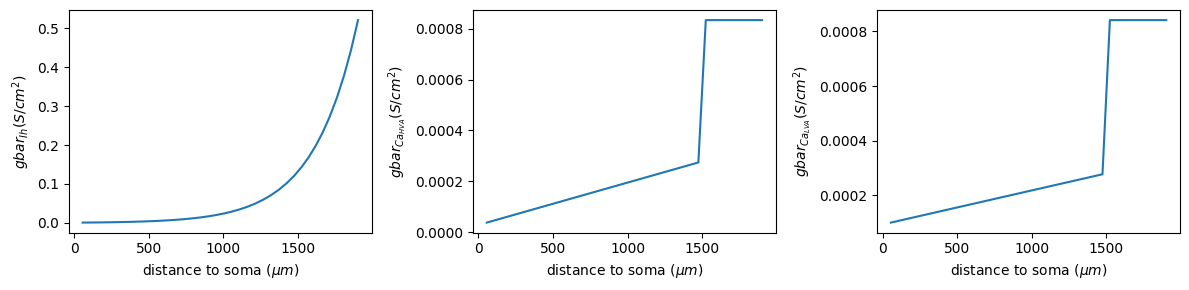

In [11]:
# get paramaters
section_params, end_pts, cell_tree = l5_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'soma': -68,
            'basal_1': -68,
            'basal_2': -68,
            'basal_3': -68,
            'apical_oblique': -68,
            'apical_trunk': -68,
            'apical_1': -68,
            'apical_2': -60,
            'apical_tuft': -54}

sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=v_init['soma'])

mech_class = Mechs(pth_mod)


hotzone = [1500, 2000]
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()

l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)


# Show conductances

fig = fig_conductances(l5pyr)

fig.savefig(os.path.join(figpth, 'conductances.png'))


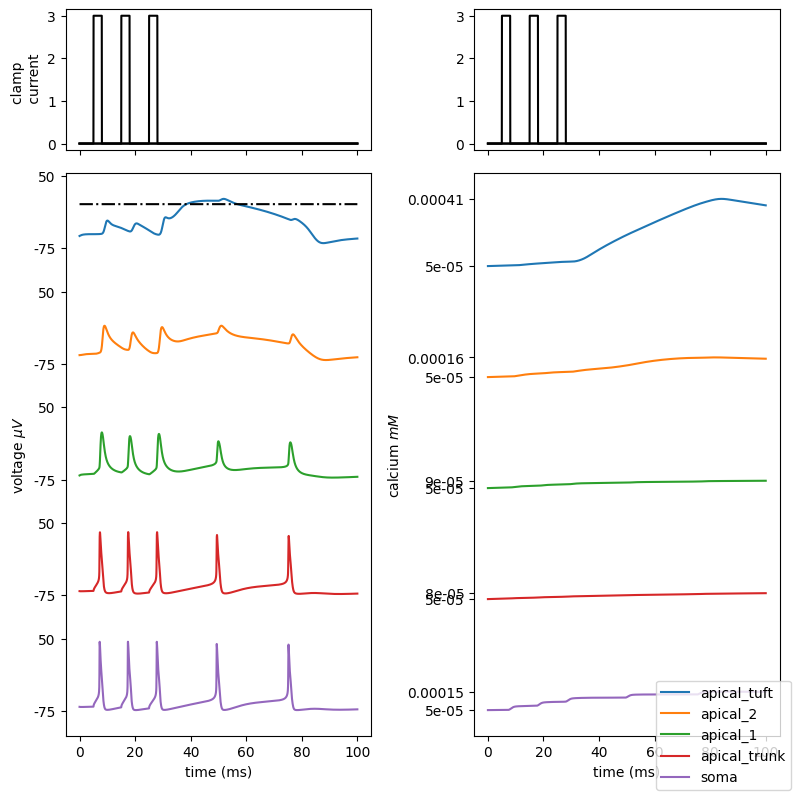

In [12]:
# Calcium spike after 3 APs at critical frequency
num_pulse = 3

stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 5+(10*i)
    stim[i].dur = 3
    stim[i].amp = 3
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)

fig, voltg, t = fig_compartments(l5pyr, clamp_current, l_stim=100)
fig.savefig(figpth+f'{str(num_pulse)}_pulses_high_CaHVA_soma.png')

In [5]:
from scipy.signal import find_peaks
peaks, props = find_peaks(voltg[-1].as_numpy(), height=0)

t.as_numpy()[peaks]

array([ 7.15 , 17.5  , 27.8  , 51.925])

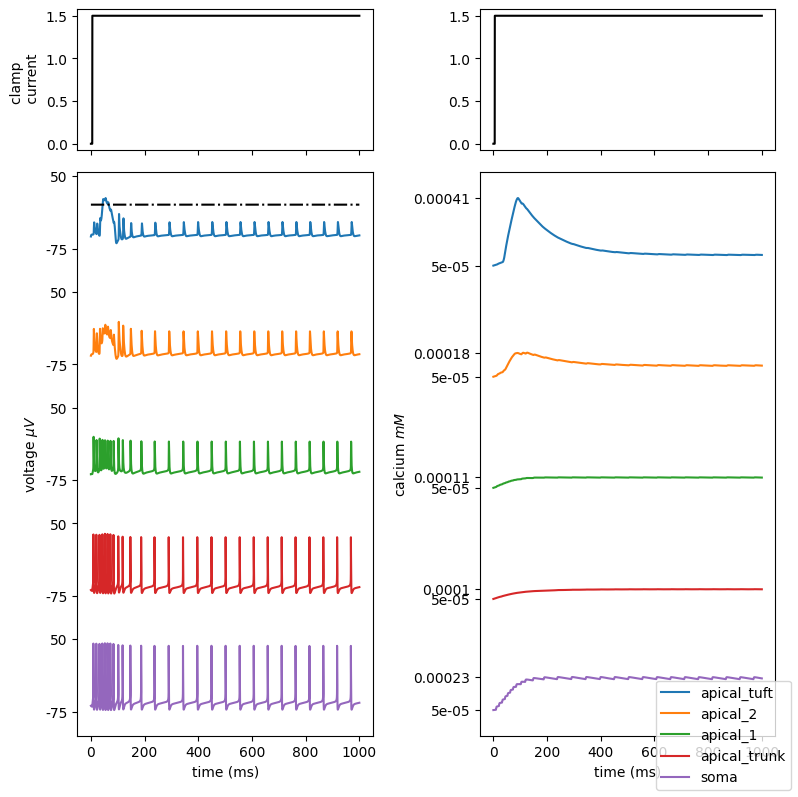

In [5]:
# burst followed by regular spikes in response to continuous input

l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

# critical freq
num_pulse = 3
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 1000
stim.amp = 1.5
clamp_current = h.Vector().record(stim._ref_i)

fig = fig_compartments(l5pyr, [clamp_current], l_stim=1000)


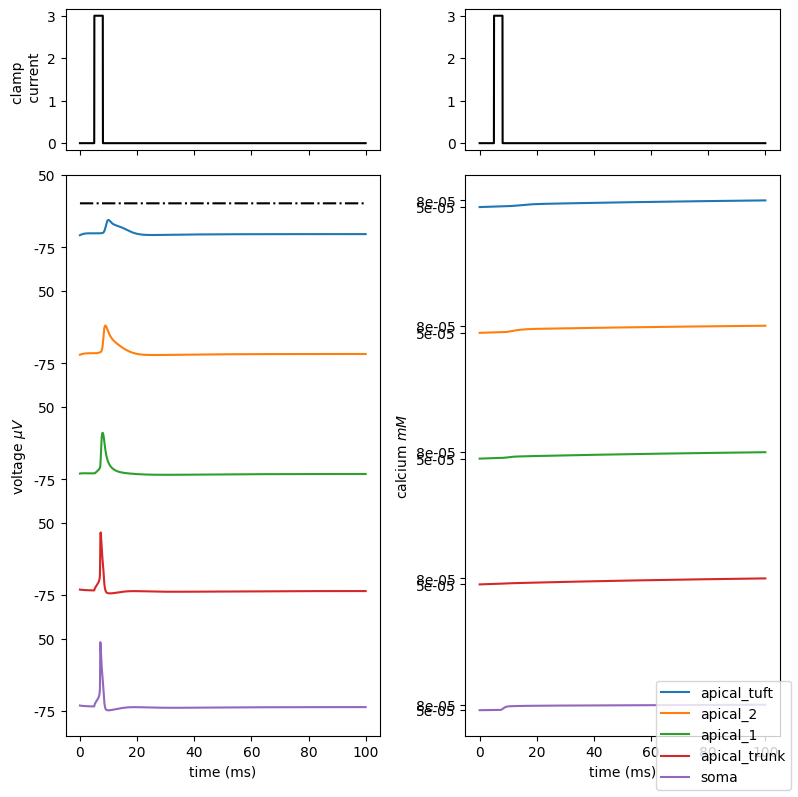

In [6]:
# somatic drive: 1 pulse -> 1 AP
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

# critical freq
num_pulse = 3
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = 3
clamp_soma = h.Vector().record(stim._ref_i)

fig = fig_compartments(l5pyr, [clamp_soma], l_stim=100)
#fig.savefig(figpth+'single_spike.png')


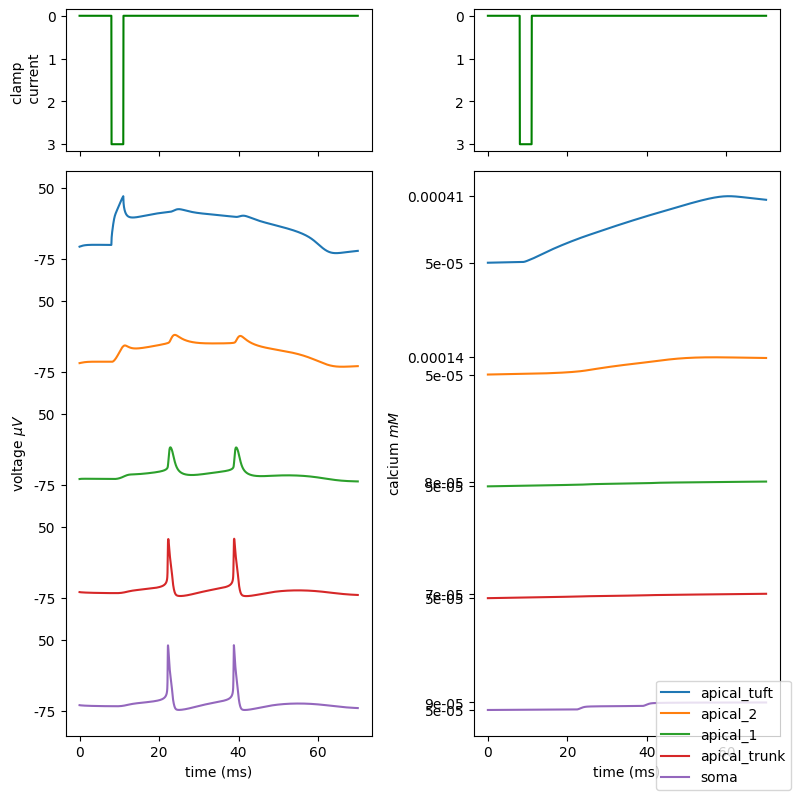

In [7]:
# weak distal drive: silence
section_names = ['apical_tuft', 'apical_2', 'apical_1', 'apical_trunk', 'soma']

l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

stim_a = h.IClamp(l5pyr._nrn_sections['apical_tuft'](0.5))
stim_a.delay = 8
stim_a.dur = 3
stim_a.amp = 3
clamp_tuft = h.Vector().record(stim_a._ref_i)


l_stim = 70
voltg = [None]*len(section_names)
ca = [None]*len(section_names)
for i, section in enumerate(section_names):
    voltg[i] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)
    ca[i] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_cai)

t = h.Vector().record(h._ref_t)


h.celsius = 37
h.finitialize()
h.continuerun(l_stim * ms)

fig, ax = plt.subplots(2,2, figsize=(8,8), height_ratios=[0.25, 1], sharex=True)

ax[0,0].plot(t, clamp_tuft, color='g')
ax[0,0].invert_yaxis()
ax[0,1].plot(t, clamp_tuft, color='g')
ax[0,1].invert_yaxis()

ax[0,0].set_ylabel('clamp \n current')
yticks_v = []
yticklabels_v = []

yticks_ca = []
yticklabels_ca = []

cv = 0
cca = 0
for i,section in enumerate(section_names):
    
    ax[1,0].plot(t,voltg[i] + cv)

    yticks_v.append(-75+cv)
    yticks_v.append(50+cv)

    yticklabels_v.append(str(np.round(-75)))
    yticklabels_v.append(str(np.round(50)))

    cv -= 200

    ax[1,1].plot(t,ca[i] + cca, label=section)

    yticks_ca.append(min(ca[i])+cca)
    yticks_ca.append(max(ca[i])+cca)

    yticklabels_ca.append(str(min(ca[i])))
    yticklabels_ca.append(str(np.round(max(ca[i]),5)))

    cca -= 6e-4


ax[1,0].set_yticks(yticks_v)
ax[1,0].set_yticklabels(yticklabels_v)
ax[1,0].set_ylabel('voltage $\mu V$')
ax[1,0].set_xlabel('time (ms)')


ax[1,1].set_yticks(yticks_ca)
ax[1,1].set_yticklabels(yticklabels_ca)
ax[1,1].set_ylabel('calcium $mM$')
ax[1,1].set_xlabel('time (ms)')
fig.legend(loc='lower right')

fig.tight_layout()
fig.savefig(figpth+'strong_distal.png')


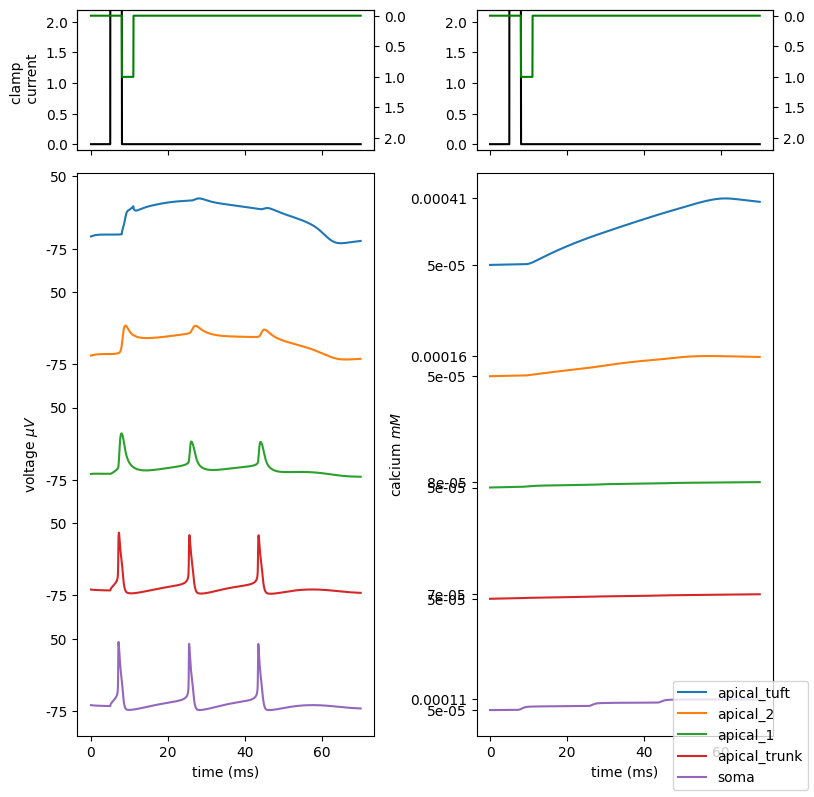

In [8]:
# put the two together: coincidence detection!

l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = 3.
clamp_soma = h.Vector().record(stim._ref_i)

stim_a = h.IClamp(l5pyr._nrn_sections['apical_tuft'](0.5))
stim_a.delay = 8
stim_a.dur = 3
stim_a.amp = 1
clamp_tuft = h.Vector().record(stim_a._ref_i)

section_names = ['apical_tuft', 'apical_2', 'apical_1', 'apical_trunk', 'soma']

l_stim = 70
voltg = [None]*len(section_names)
ca = [None]*len(section_names)
for i, section in enumerate(section_names):
    voltg[i] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)
    ca[i] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_cai)

t = h.Vector().record(h._ref_t)


h.celsius = 37
h.finitialize()
h.continuerun(l_stim * ms)

fig, ax = plt.subplots(2,2, figsize=(8,8), height_ratios=[0.25, 1], sharex=True)

ax[0,0].plot(t, clamp_soma, color='k')
ax[0,0].set_ylim([-0.1, 2.2])
ax2 = ax[0,0].twinx()
ax2.plot(t, clamp_tuft, color='g')
ax2.set_ylim([-0.1, 2.2])

ax2.invert_yaxis()
ax[0,1].plot(t, clamp_soma, color='k')
ax[0,1].set_ylim([-0.1, 2.2])

ax2 = ax[0,1].twinx()
ax2.plot(t, clamp_tuft, color='g')
ax2.set_ylim([-0.1, 2.2])
ax2.invert_yaxis()

ax[0,0].set_ylabel('clamp \n current')
yticks_v = []
yticklabels_v = []

yticks_ca = []
yticklabels_ca = []

cv = 0
cca = 0
for i,section in enumerate(section_names):
    
    ax[1,0].plot(t,voltg[i] + cv)

    yticks_v.append(-75+cv)
    yticks_v.append(50+cv)

    yticklabels_v.append(str(np.round(-75)))
    yticklabels_v.append(str(np.round(50)))

    cv -= 200

    ax[1,1].plot(t,ca[i] + cca, label=section)

    yticks_ca.append(min(ca[i])+cca)
    yticks_ca.append(max(ca[i])+cca)

    yticklabels_ca.append(str(min(ca[i])))
    yticklabels_ca.append(str(np.round(max(ca[i]),5)))

    cca -= 6e-4


ax[1,0].set_yticks(yticks_v)
ax[1,0].set_yticklabels(yticklabels_v)
ax[1,0].set_ylabel('voltage $\mu V$')
ax[1,0].set_xlabel('time (ms)')


ax[1,1].set_yticks(yticks_ca)
ax[1,1].set_yticklabels(yticklabels_ca)
ax[1,1].set_ylabel('calcium $mM$')
ax[1,1].set_xlabel('time (ms)')
fig.legend(loc='lower right')

fig.tight_layout()

fig.savefig(figpth+'coincidence_detection.png')


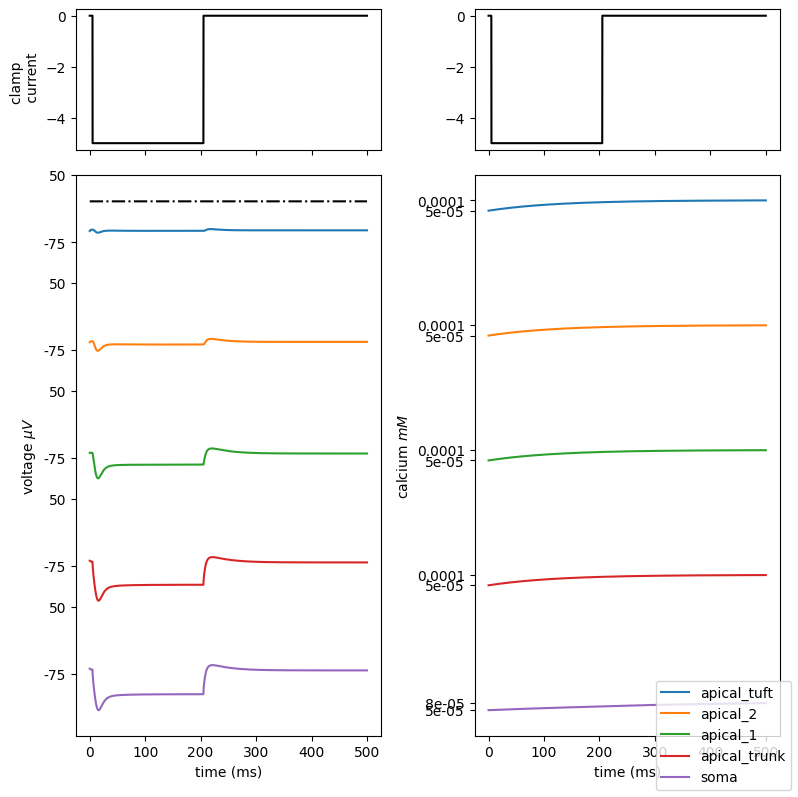

In [18]:
# hyperpolarization rebound

l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

# critical freq
num_pulse = 3
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 200
stim.amp = -5
clamp_current = h.Vector().record(stim._ref_i)

fig = fig_compartments(l5pyr, [clamp_current], l_stim=500)

In [ ]:
# rheobase
from scipy.signal import find_peaks

ampl = np.arange(0.5,1.5,0.05)

for a in ampl:
    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

    # critical freq
    num_pulse = 3
    stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 1000
    stim.amp = a
    clamp_current = h.Vector().record(stim._ref_i)

    v = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)


    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(200 * ms)

    pk = find_peaks(v, height=0)
    if np.any(pk[0]) == True:
        print(f'lowest ampl to induce spike: {a}')
        break

fig, ax = plt.subplots(2,1)

ax[0].plot(t,clamp_current)
ax[0].set_ylabel('clamp current')
ax[1].plot(t,v)
ax[1].set_xlabel('time (s)')
ax[1].set_ylabel('membrane potential $\mu V$')
ax[0].set_title('rheobase L5 cell')

fig.savefig(figpth+'rheobase.png')
    

# add basal dendrites

In [ ]:
l5pyr.sections['soma'].end_pts

In [ ]:
ax = plt.figure().add_subplot(projection='3d')
plot_cell_morphology(l5pyr, ax=ax, show=False)
ax.view_init(0,80)


HNN cell_default: proximal drive is basal_2, basal_3 and apical_oblique https://github.com/jonescompneurolab/hnn-core/blob/master/hnn_core/cells_default.py#L115

In [ ]:
def epsp_sim(sections, cell_tree, epsp_strength = 1):

    # check EPSP effect
    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

    syn_inp = h.epsp(l5pyr._nrn_sections['basal_2'](0.9))
    syn_inp.onset = 5
    syn_inp.imax = epsp_strength

    h.distance(sec = l5pyr._nrn_sections['soma'])
    segments = [seg.x for seg in l5pyr._nrn_sections['basal_2']]

    voltg_basal = [None]*len(segments)
    for i, seg in enumerate(l5pyr._nrn_sections['basal_2']):
        voltg_basal[i] = h.Vector().record(seg._ref_v)

    voltg_apical = [None]*len(section_names)
    for i, section in enumerate(section_names):
        voltg_apical[i] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    l_stim = 100
    h.celsius = 34
    h.finitialize(-65 * mV)
    h.continuerun(l_stim * ms)

    return segments, voltg_basal, voltg_apical, t

In [ ]:
fig, ax = plt.subplots(2,5,figsize=(20,8))


for a, epsp_strength in enumerate(np.linspace(1,2.5,5)):
    segments, voltg_basal, voltg_apical, t = epsp_sim(sections, cell_tree, epsp_strength)

    for i,v in enumerate(voltg_basal):
        ax[0, a].plot(t,v, label=str(segments[i]))

    ax[0, a].legend()
    ax[0, a].set_title(f'EPSP basal_2 strength {str(np.round(epsp_strength,2))}')
    ax[0, a].set_ylabel('voltage $\mu V$')

    for i,v in enumerate(voltg_apical):
        ax[1, a].plot(t,v, label=section_names[i])
    ax[1, a].legend()
    ax[1, a].set_title('cell response')
    ax[1, a].set_ylabel('voltage $\mu V$')

    fig.savefig(figpth+'basal_dendrites_epsps.png')

In [ ]:
# Compare Ih Rich et al., 2021 vs Hay et al., 2011

In [ ]:
def _exp_g_at_dist(x, zero_val, exp_term, offset, slope=1):
    """Compute exponential distance-dependent ionic conductance.

    Parameters
    ----------
    x : float | int
        Distance from soma
    zero_val : float | int
        Value of function when x = 0
    exp_term : float | int
        Multiplier of x in the exponent
    offset: float |int
        Offset value added to output

    """

    return zero_val * (slope * np.exp(exp_term * x)  + offset)

In [ ]:
fig, ax = plt.subplots()

distance = np.linspace(0,2000,20000)

rich_Ih = _exp_g_at_dist(distance, zero_val=5.14e-5, exp_term=3.6161/1000, offset=-0.8696, slope=2.087)
hay_Ih = _exp_g_at_dist(distance, zero_val=2e-4, exp_term=1/323, offset=-0.8696, slope=2.087)
new_cell = _exp_g_at_dist(distance, zero_val=1e-4, exp_term=1/323, offset=-0.8696, slope=5)

ax.plot(distance,hay_Ih,label='Hay')
ax.plot(distance,rich_Ih,label='Rich')
ax.plot(distance, new_cell, label='new_model')
ax.legend()

fig.savefig(figpth+'Ih_conductance.png')